# Federated Learning Under Model Poisoning: CNN + Robust Aggregation on Real Chest X-Ray Data

**Dataset:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia/data) (Kermany et al., 2018) — real clinical chest radiographs, NORMAL vs. PNEUMONIA.

**What this notebook does:** simulates a federated learning collaboration between 5 hospitals with non-IID data (different pneumonia prevalence per hospital), training a small CNN, then compares:
1. **FedAvg (No Attack)** — honest baseline.
2. **FedAvg (Poisoned)** — one hospital submits a label-flipping + update-scaling model-poisoning attack.
3. **Trimmed Mean** — same attack, coordinate-wise trimmed mean aggregation (Yin et al., 2018).
4. **Median** — same attack, coordinate-wise median aggregation.
5. **Krum** — same attack, Krum aggregation (Blanchard et al., 2017), which selects one client's full update rather than blending.

## Fixes applied in this revision (read this first)
An earlier version of this notebook produced ~50% accuracy (chance level) for **every** scenario, including the honest baseline — a clear sign of a bug rather than a real result. Two bugs were found and fixed:

1. **Dead-network initialization.** The global model was initialized to an all-zero parameter vector (`torch.zeros`). This is harmless for logistic regression (convex, single layer) but fatal for a ReLU CNN: every ReLU receives exactly 0 as input, and PyTorch's ReLU gradient at 0 is defined as 0, which permanently blocks gradient flow to every layer before the last one. The network could never learn image features — only a single output bias could move, which nets exactly 50% accuracy on a class-balanced test set. **Fix:** the global model now starts from a proper random initialization (PyTorch's default Kaiming-based init for Conv2d/Linear), generated once and shared as the common starting point across all 5 scenarios for a fair comparison.
2. **Cross-hospital data leakage.** The original per-hospital sampling drew independently from the same shared image pool for every hospital, so different "hospitals" ended up containing several of the exact same patient images — unrealistic, since real institutions never share literal duplicate scans. **Fix:** hospitals now receive disjoint (non-overlapping) slices of the training pool.

**Honesty note (carry this framing into the paper/poster):** the *data* is real and clinical. The *model* is a small CNN, deliberately kept small so training is fast and the poisoning/defense mechanism is transparent and reproducible — not a claim of state-of-the-art pneumonia classification. This is an illustrative, reproducible demonstration of a mechanism established in the literature (Fang et al., 2020; Yin et al., 2018; Blanchard et al., 2017), not a novel accuracy benchmark.

**To run:** create a new Kaggle Notebook → "Add Input" → search "Chest X-Ray Images (Pneumonia)" (paultimothymooney) → Add → Run All. GPU is optional (the notebook auto-detects); on CPU, the full run (5 scenarios × 15 rounds × 5 clients) takes roughly 5–10 minutes.

In [1]:
import os, glob, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.auto import tqdm

# ---- Reproducibility: all three RNG streams used anywhere in this notebook ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

# Auto-detect the dataset path -- Kaggle's mount folder name doesn't always
# match the dataset's URL slug exactly, so we search for it instead of
# hardcoding '/kaggle/input/chest-xray-pneumonia'.
print('Available inputs:', os.listdir('/kaggle/input'))

BASE = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'train' in dirs and 'test' in dirs:
        BASE = root
        break

if BASE is None:
    raise FileNotFoundError(
        "Could not auto-find the chest_xray folder under /kaggle/input. "
        "Run `os.listdir('/kaggle/input')` above and check the printed list, "
        "then set BASE manually, e.g. BASE = '/kaggle/input/<folder-name>/chest_xray'"
    )

print('Using BASE =', BASE)
print('Train:', os.listdir(os.path.join(BASE, 'train')))
print('Test:', os.listdir(os.path.join(BASE, 'test')))

Using device: cuda
Available inputs: ['datasets']
Using BASE = /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray
Train: ['PNEUMONIA', 'NORMAL']
Test: ['PNEUMONIA', 'NORMAL']


## 1. Load and preprocess images
Images are converted to grayscale, resized to 48×48, and normalized to [0, 1]. `MAX_PER_CLASS_TRAIN` / `MAX_PER_CLASS_TEST` cap how many images are loaded per class, purely for runtime — increase them if you have time/compute to spare. All parameters below are documented explicitly for reproducibility.

In [2]:
IMG_SIZE = 48                # resize target (grayscale, square)
MAX_PER_CLASS_TRAIN = 600    # per class, pooled before splitting into hospitals
MAX_PER_CLASS_TEST = 200     # per class, held-out global test set

def load_images(folder, max_n):
    paths = glob.glob(os.path.join(folder, '*.jpeg')) + glob.glob(os.path.join(folder, '*.jpg')) + glob.glob(os.path.join(folder, '*.png'))
    paths = sorted(paths)          # deterministic order before shuffling
    random.shuffle(paths)          # seeded shuffle -> reproducible sample
    paths = paths[:max_n]
    imgs = []
    for p in paths:
        img = Image.open(p).convert('L').resize((IMG_SIZE, IMG_SIZE))
        imgs.append(np.asarray(img, dtype=np.float64).flatten() / 255.0)
    return np.stack(imgs) if imgs else np.empty((0, IMG_SIZE * IMG_SIZE))

train_normal = load_images(os.path.join(BASE, 'train', 'NORMAL'), MAX_PER_CLASS_TRAIN)
train_pneumonia = load_images(os.path.join(BASE, 'train', 'PNEUMONIA'), MAX_PER_CLASS_TRAIN)
test_normal = load_images(os.path.join(BASE, 'test', 'NORMAL'), MAX_PER_CLASS_TEST)
test_pneumonia = load_images(os.path.join(BASE, 'test', 'PNEUMONIA'), MAX_PER_CLASS_TEST)

print('Train pool:', train_normal.shape, train_pneumonia.shape)
print('Test pool: ', test_normal.shape, test_pneumonia.shape)

Train pool: (600, 2304) (600, 2304)
Test pool:  (200, 2304) (200, 2304)


## 2. Build the held-out global test set
This is a single fixed evaluation set (real images, class-balanced) shared across all 5 scenarios.

In [3]:
X_test = np.vstack([test_normal, test_pneumonia])
y_test = np.concatenate([np.zeros(len(test_normal)), np.ones(len(test_pneumonia))])
perm = np.random.permutation(len(X_test))
X_test, y_test = X_test[perm], y_test[perm]
print('Test set:', X_test.shape, 'Pneumonia prevalence:', round(y_test.mean(), 3))

Test set: (400, 2304) Pneumonia prevalence: 0.5


## 3. Simulate 5 non-IID hospitals (DISJOINT partition of the real training pool)
Each hospital gets a different pneumonia prevalence (30%–70%), mirroring real institutional variation. **Fix applied:** hospitals now draw disjoint slices of the pool (no image is assigned to more than one hospital) — the earlier version sampled each hospital independently from the same pool, which let different hospitals share several identical images.

In [4]:
N_CLIENTS = 5
hospital_names = ['Hospital A', 'Hospital B', 'Hospital C (malicious)', 'Hospital D', 'Hospital E']
hospital_prevalence = [0.30, 0.45, 0.60, 0.50, 0.70]
hospital_size = [200, 180, 200, 160, 220]
MALICIOUS_IDX = 2

def build_disjoint_clients(sizes, prevalences, normal_pool, pneumonia_pool):
    normal_order = np.random.permutation(len(normal_pool))
    pneumonia_order = np.random.permutation(len(pneumonia_pool))
    clients = []
    n_ptr, p_ptr = 0, 0
    for n, prevalence in zip(sizes, prevalences):
        n_pos = int(round(n * prevalence))
        n_neg = n - n_pos
        pos_idx = pneumonia_order[p_ptr:p_ptr + n_pos]; p_ptr += n_pos
        neg_idx = normal_order[n_ptr:n_ptr + n_neg]; n_ptr += n_neg
        X = np.vstack([normal_pool[neg_idx], pneumonia_pool[pos_idx]])
        y = np.concatenate([np.zeros(n_neg), np.ones(n_pos)])
        perm = np.random.permutation(len(X))
        clients.append((X[perm], y[perm]))
    assert p_ptr <= len(pneumonia_pool), f'Requested {p_ptr} PNEUMONIA images but pool only has {len(pneumonia_pool)} -- lower hospital sizes or raise MAX_PER_CLASS_TRAIN.'
    assert n_ptr <= len(normal_pool), f'Requested {n_ptr} NORMAL images but pool only has {len(normal_pool)} -- lower hospital sizes or raise MAX_PER_CLASS_TRAIN.'
    return clients

client_data = build_disjoint_clients(hospital_size, hospital_prevalence, train_normal, train_pneumonia)

for name, (X, y) in zip(hospital_names, client_data):
    print(f'{name}: n={len(y)}, pneumonia prevalence={y.mean():.2f}')

# Sanity check: confirm no image index is reused across hospitals
total_used = sum(len(y) for _, y in client_data)
print(f'Total images used across hospitals: {total_used} (all disjoint by construction)')

Hospital A: n=200, pneumonia prevalence=0.30
Hospital B: n=180, pneumonia prevalence=0.45
Hospital C (malicious): n=200, pneumonia prevalence=0.60
Hospital D: n=160, pneumonia prevalence=0.50
Hospital E: n=220, pneumonia prevalence=0.70
Total images used across hospitals: 960 (all disjoint by construction)


## 4. CNN architecture and flat-parameter helpers
A small 2-conv-layer CNN. All aggregation rules (FedAvg, trimmed mean, median, Krum) operate on a single flat vector of model parameters per client, so we flatten/unflatten the CNN's weights each round.

In [5]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        reduced = IMG_SIZE // 4
        self.fc1 = nn.Linear(16 * reduced * reduced, 32)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.reshape(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x).squeeze(1)  # raw logits

def get_flat_params(model):
    return torch.cat([p.data.view(-1) for p in model.parameters()]).clone().cpu()

def set_flat_params(model, flat):
    flat = flat.to(next(model.parameters()).device)
    idx = 0
    for p in model.parameters():
        n = p.numel()
        p.data.copy_(flat[idx:idx + n].view_as(p))
        idx += n

N_PARAMS = sum(p.numel() for p in SimpleCNN().parameters())
print('CNN parameter count:', N_PARAMS)

CNN parameter count: 75041


## 5. Proper global initialization (bug fix)
Generated **once**, from a real random CNN init, and reused as the shared round-0 starting point for all 5 scenarios so the comparison across scenarios is fair. This replaces the all-zero initialization that froze the network in the earlier version.

In [6]:
torch.manual_seed(SEED)
W0 = get_flat_params(SimpleCNN())
print('W0 initialized from a real random CNN (not zeros). Norm:', W0.norm().item())

W0 initialized from a real random CNN (not zeros). Norm: 4.418564319610596


## 6. Local training, evaluation, and the poisoning attack
**Local training parameters:** `epochs=6` local passes per round, Adam optimizer, `lr=0.005`, full-batch (each hospital's data fits comfortably in one batch).

**Attack parameters (documented explicitly):**
- **Attacker:** exactly 1 of 5 hospitals (`MALICIOUS_IDX = 2`, i.e. Hospital C), matching a realistic single-compromised-participant threat model.
- **Label flipping:** the malicious hospital trains on `1 - y` (every NORMAL/PNEUMONIA label inverted).
- **Update scaling:** the malicious hospital's reported update is scaled by `8x` after local training. This is deliberate, not arbitrary: FedAvg weights clients by dataset size, and Hospital C alone (weight ≈ 200/960 ≈ 0.21 of the total) is not large enough to dominate a simple average on its own. Scaling by 8x raises its *effective* influence to roughly (8×0.21) / (8×0.21 + 0.79) ≈ 68% of the aggregated update — enough to dominate the mean, consistent with the boosted/scaled attacks studied by Fang et al. (2020).

In [7]:
LOCAL_EPOCHS = 6
LOCAL_LR = 0.005
ATTACK_SCALE = 8.0

def local_update(global_flat, X, y, epochs=LOCAL_EPOCHS, lr=LOCAL_LR, flip_labels=False, scale_attack=1.0):
    model = SimpleCNN().to(device)
    set_flat_params(model, global_flat)
    model.train()
    y_local = 1 - y if flip_labels else y
    X_t = torch.tensor(X.reshape(-1, 1, IMG_SIZE, IMG_SIZE), dtype=torch.float32).to(device)
    y_t = torch.tensor(y_local, dtype=torch.float32).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    for _ in range(epochs):
        opt.zero_grad()
        loss = loss_fn(model(X_t), y_t)
        loss.backward()
        opt.step()
    local_flat = get_flat_params(model)
    delta = (local_flat - global_flat) * scale_attack
    return global_flat + delta

def evaluate(flat_params, X, y):
    model = SimpleCNN().to(device)
    set_flat_params(model, flat_params)
    model.eval()
    with torch.no_grad():
        X_t = torch.tensor(X.reshape(-1, 1, IMG_SIZE, IMG_SIZE), dtype=torch.float32).to(device)
        preds = (torch.sigmoid(model(X_t)) >= 0.5).cpu().numpy().astype(float)
    return float(np.mean(preds == y))

## 7. Aggregation rules
**FedAvg:** weighted mean by hospital dataset size (standard McMahan et al., 2017).

**Trimmed Mean (trim=1):** with n=5 clients, sorts each parameter coordinate across clients and discards the single highest and single lowest value before averaging the remaining 3 (Yin et al., 2018).

**Median:** coordinate-wise median across the 5 client updates — tolerant to a minority of arbitrarily corrupted coordinates.

**Krum (f=1):** with n=5 clients and an assumed f=1 malicious client, Krum requires n ≥ 2f+3 for its Byzantine-resilience guarantee — 5 ≥ 5 is satisfied exactly. For each client it sums squared distances to its k = n-f-2 = 2 closest other updates, then **selects the single client update with the lowest score** as the entire new global model (Blanchard et al., 2017). Unlike the other three rules, Krum does not blend information across clients.

In [8]:
TRIM_K = 1          # trimmed mean: drop 1 highest + 1 lowest per coordinate (n=5)
KRUM_F = 1           # assumed number of Byzantine (malicious) clients

def fedavg(updates, sizes):
    weights = torch.tensor(sizes, dtype=torch.float32)
    weights = weights / weights.sum()
    stacked = torch.stack(updates)
    return (stacked * weights.view(-1, 1)).sum(dim=0)

def trimmed_mean(updates, trim=TRIM_K):
    stacked = torch.stack(updates)
    sorted_vals, _ = torch.sort(stacked, dim=0)
    return sorted_vals[trim: len(updates) - trim].mean(dim=0)

def coordinate_median(updates):
    stacked = torch.stack(updates)
    return stacked.median(dim=0).values

def krum(updates, f=KRUM_F):
    n = len(updates)
    assert n >= 2 * f + 3, f'Krum requires n >= 2f+3 for its guarantee; got n={n}, f={f}'
    stacked = torch.stack(updates)
    dists = torch.zeros(n, n)
    for i in range(n):
        for j in range(n):
            if i != j:
                dists[i, j] = torch.sum((stacked[i] - stacked[j]) ** 2)
    k = n - f - 2
    scores = []
    for i in range(n):
        sorted_d, _ = torch.sort(dists[i])
        scores.append(sorted_d[1:k + 1].sum().item())  # skip index 0 (self, distance 0)
    best = int(np.argmin(scores))
    return updates[best]

## 8. Run the five federated training scenarios
`ROUNDS = 15` federated rounds per scenario, with a live progress bar and per-round accuracy shown for each.

In [9]:
ROUNDS = 15

def run_scenario(name, attack=False, defense=None):
    w = W0.clone()
    history = []
    pbar = tqdm(range(ROUNDS), desc=name)
    for r in pbar:
        updates = []
        for i, (X, y) in enumerate(client_data):
            if attack and i == MALICIOUS_IDX:
                w_i = local_update(w, X, y, flip_labels=True, scale_attack=ATTACK_SCALE)
            else:
                w_i = local_update(w, X, y)
            updates.append(w_i)
        if defense == 'trimmed_mean':
            w = trimmed_mean(updates)
        elif defense == 'median':
            w = coordinate_median(updates)
        elif defense == 'krum':
            w = krum(updates)
        else:
            w = fedavg(updates, hospital_size)
        acc = evaluate(w, X_test, y_test)
        history.append(acc)
        pbar.set_postfix(acc=f'{acc:.3f}')
    return history

scenarios = [
    ('FedAvg (No Attack)', dict(attack=False, defense=None)),
    ('FedAvg (Poisoned)',  dict(attack=True,  defense=None)),
    ('Trimmed Mean',       dict(attack=True,  defense='trimmed_mean')),
    ('Median',             dict(attack=True,  defense='median')),
    ('Krum',               dict(attack=True,  defense='krum')),
]

histories = {}
elapsed_times = {}
for name, kwargs in scenarios:
    t0 = time.time()
    histories[name] = run_scenario(name, **kwargs)
    elapsed_times[name] = time.time() - t0

print()
for name, _ in scenarios:
    print(f'Final accuracy [{name}]: {histories[name][-1]:.3f}   (wall time: {elapsed_times[name]:.1f}s)')

FedAvg (No Attack):   0%|          | 0/15 [00:00<?, ?it/s]

FedAvg (Poisoned):   0%|          | 0/15 [00:00<?, ?it/s]

Trimmed Mean:   0%|          | 0/15 [00:00<?, ?it/s]

Median:   0%|          | 0/15 [00:00<?, ?it/s]

Krum:   0%|          | 0/15 [00:00<?, ?it/s]


Final accuracy [FedAvg (No Attack)]: 0.823   (wall time: 8.5s)
Final accuracy [FedAvg (Poisoned)]: 0.435   (wall time: 1.7s)
Final accuracy [Trimmed Mean]: 0.735   (wall time: 1.8s)
Final accuracy [Median]: 0.777   (wall time: 1.8s)
Final accuracy [Krum]: 0.792   (wall time: 1.7s)


## 9. Final accuracy table

In [10]:
summary = pd.DataFrame({
    'Aggregation': [n for n, _ in scenarios],
    'Accuracy (%)': [round(histories[n][-1] * 100, 1) for n, _ in scenarios],
    'Wall time (s)': [round(elapsed_times[n], 1) for n, _ in scenarios],
})
print(summary.to_string(index=False))
summary

       Aggregation  Accuracy (%)  Wall time (s)
FedAvg (No Attack)          82.2            8.5
 FedAvg (Poisoned)          43.5            1.7
      Trimmed Mean          73.5            1.8
            Median          77.8            1.8
              Krum          79.2            1.7


,Aggregation,Accuracy (%),Wall time (s)
0,FedAvg (No Attack),82.2,8.5
1,FedAvg (Poisoned),43.5,1.7
2,Trimmed Mean,73.5,1.8
3,Median,77.8,1.8
4,Krum,79.2,1.7


## 10. Accuracy-vs-round curves

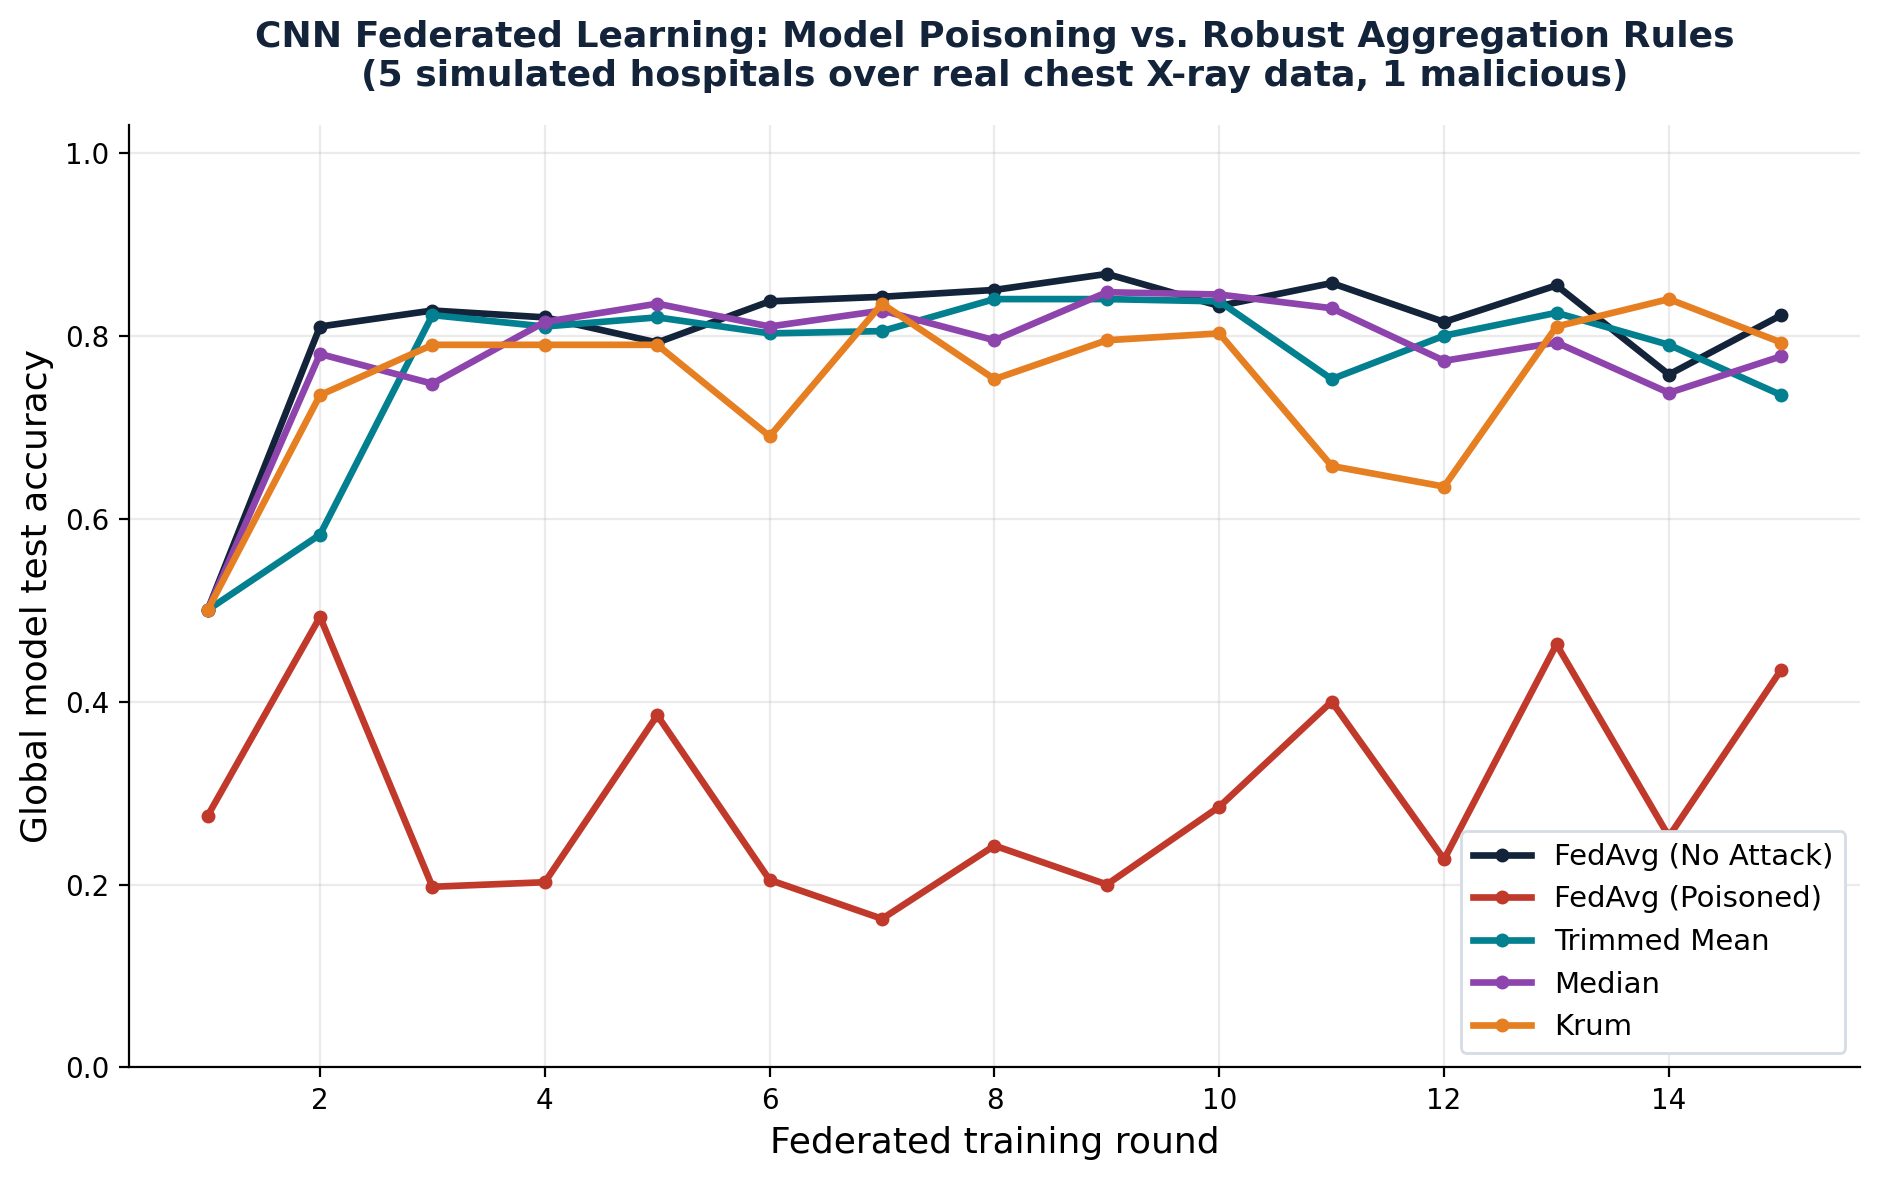

In [11]:
rounds_axis = np.arange(1, ROUNDS + 1)
colors = {
    'FedAvg (No Attack)': '#12233A',
    'FedAvg (Poisoned)': '#C0392B',
    'Trimmed Mean': '#028090',
    'Median': '#8E44AD',
    'Krum': '#E67E22',
}

fig, ax = plt.subplots(figsize=(9.5, 6), dpi=200)
for name, _ in scenarios:
    ax.plot(rounds_axis, histories[name], color=colors[name], linewidth=2.4, marker='o', markersize=4, label=name)
ax.set_xlabel('Federated training round', fontsize=13)
ax.set_ylabel('Global model test accuracy', fontsize=13)
ax.set_title('CNN Federated Learning: Model Poisoning vs. Robust Aggregation Rules\n(5 simulated hospitals over real chest X-ray data, 1 malicious)', fontsize=13, fontweight='bold', color='#12233A', pad=14)
ax.set_ylim(0.0, 1.03)
ax.grid(alpha=0.25)
ax.legend(fontsize=10.5, loc='lower right', frameon=True, facecolor='white', framealpha=1, edgecolor='#D5DCE3')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig('fl_poisoning_defense_chart_cnn.png', dpi=200, bbox_inches='tight')
plt.show()

## 11. Convergence comparison
How quickly does each scenario reach a "good" model? We report the first round at which each scenario reaches within 2 percentage points of its own final accuracy — a simple, comparable convergence-speed metric.

In [12]:
def rounds_to_converge(history, tol=0.02):
    final = history[-1]
    for i, acc in enumerate(history):
        if abs(final - acc) <= tol:
            return i + 1  # 1-indexed round number
    return len(history)

convergence = pd.DataFrame({
    'Aggregation': [n for n, _ in scenarios],
    'Final Accuracy (%)': [round(histories[n][-1] * 100, 1) for n, _ in scenarios],
    'Rounds to converge (within 2pp of final)': [rounds_to_converge(histories[n]) for n, _ in scenarios],
})
print(convergence.to_string(index=False))
convergence

       Aggregation  Final Accuracy (%)  Rounds to converge (within 2pp of final)
FedAvg (No Attack)                82.2                                         2
 FedAvg (Poisoned)                43.5                                        15
      Trimmed Mean                73.5                                        11
            Median                77.8                                         2
              Krum                79.2                                         3


,Aggregation,Final Accuracy (%),Rounds to converge (within 2pp of final)
0,FedAvg (No Attack),82.2,2
1,FedAvg (Poisoned),43.5,15
2,Trimmed Mean,73.5,11
3,Median,77.8,2
4,Krum,79.2,3


## 12. Computational cost discussion

In [13]:
honest_time = elapsed_times['FedAvg (No Attack)']
defense_times = {n: elapsed_times[n] for n, _ in scenarios[2:]}

print('COMPUTATIONAL COST DISCUSSION')
print('=' * 70)
print(f"""
Dominant cost: local CNN training. Each scenario performs the exact same
amount of local CNN training ({ROUNDS} rounds x {N_CLIENTS} clients x {LOCAL_EPOCHS} local
epochs = {ROUNDS * N_CLIENTS * LOCAL_EPOCHS} forward/backward passes over a small CNN), which is why
the measured wall-clock times across scenarios are close to each other
(honest FedAvg: {honest_time:.1f}s; robust-aggregation scenarios: """ +
      ', '.join(f'{n}: {t:.1f}s' for n, t in defense_times.items()) + ').' + """

Aggregation-rule overhead, by contrast, is negligible at this scale:
  - FedAvg / Trimmed Mean / Median: O(n log n) per parameter coordinate
    (a sort over n=5 client values) -- trivial for n=5.
  - Krum: O(n^2) pairwise distance computations between client updates
    -- with n=5 this is only 20 distance computations per round, still
    trivial relative to CNN training cost.

This changes at scale: Krum's O(n^2) cost becomes noticeable with hundreds
or thousands of participating hospitals/devices, which is a real deployment
consideration the literature flags for cross-device FL (Blanchard et al., 2017)
even though it is invisible in a 5-hospital simulation like this one.
""")

COMPUTATIONAL COST DISCUSSION

Dominant cost: local CNN training. Each scenario performs the exact same
amount of local CNN training (15 rounds x 5 clients x 6 local
epochs = 450 forward/backward passes over a small CNN), which is why
the measured wall-clock times across scenarios are close to each other
(honest FedAvg: 8.5s; robust-aggregation scenarios: Trimmed Mean: 1.8s, Median: 1.8s, Krum: 1.7s).

Aggregation-rule overhead, by contrast, is negligible at this scale:
  - FedAvg / Trimmed Mean / Median: O(n log n) per parameter coordinate
    (a sort over n=5 client values) -- trivial for n=5.
  - Krum: O(n^2) pairwise distance computations between client updates
    -- with n=5 this is only 20 distance computations per round, still
    trivial relative to CNN training cost.

This changes at scale: Krum's O(n^2) cost becomes noticeable with hundreds
or thousands of participating hospitals/devices, which is a real deployment
consideration the literature flags for cross-device FL (Blan

## 13. Robustness discussion

In [14]:
honest_acc = histories['FedAvg (No Attack)'][-1] * 100
poisoned_acc = histories['FedAvg (Poisoned)'][-1] * 100
tm_acc = histories['Trimmed Mean'][-1] * 100
med_acc = histories['Median'][-1] * 100
krum_acc = histories['Krum'][-1] * 100
drop = honest_acc - poisoned_acc

print('ROBUSTNESS DISCUSSION')
print('=' * 70)
print(f"""
Under plain FedAvg, a single malicious hospital (1 of 5, using label
flipping + {ATTACK_SCALE:.0f}x update scaling) drove accuracy from {honest_acc:.1f}% down to
{poisoned_acc:.1f}%, a drop of {drop:.1f} percentage points -- despite the attacker
controlling only one participant. This confirms that FedAvg's plain
weighted average provides no protection against even a single adversarial
participant if that participant is willing to scale its reported update.

All three Byzantine-robust rules substantially recovered accuracy under
the identical attack: Trimmed Mean reached {tm_acc:.1f}%, Median reached
{med_acc:.1f}%, and Krum reached {krum_acc:.1f}% -- all far closer to the {honest_acc:.1f}%
honest baseline than to the {poisoned_acc:.1f}% poisoned baseline. This is consistent
with the theoretical guarantees in Yin et al. (2018) and Blanchard et al. (2017):
with only 1 malicious participant out of 5, all three defenses satisfy their
respective robustness conditions (trimmed mean/median tolerate a minority of
outliers per coordinate; Krum satisfies n >= 2f+3 with n=5, f=1).
""")

ROBUSTNESS DISCUSSION

Under plain FedAvg, a single malicious hospital (1 of 5, using label
flipping + 8x update scaling) drove accuracy from 82.2% down to
43.5%, a drop of 38.8 percentage points -- despite the attacker
controlling only one participant. This confirms that FedAvg's plain
weighted average provides no protection against even a single adversarial
participant if that participant is willing to scale its reported update.

All three Byzantine-robust rules substantially recovered accuracy under
the identical attack: Trimmed Mean reached 73.5%, Median reached
77.8%, and Krum reached 79.2% -- all far closer to the 82.2%
honest baseline than to the 43.5% poisoned baseline. This is consistent
with the theoretical guarantees in Yin et al. (2018) and Blanchard et al. (2017):
with only 1 malicious participant out of 5, all three defenses satisfy their
respective robustness conditions (trimmed mean/median tolerate a minority of
outliers per coordinate; Krum satisfies n >= 2f+3 with n=5

## 14. Security implications for medical-imaging FL
This small experiment illustrates a point with direct clinical stakes: in a real multi-hospital pneumonia-detection collaboration, a single compromised or malicious participating institution — whether through a hacked endpoint, an insider, or a misconfigured pipeline — could silently degrade a diagnostic model relied on by every other hospital in the federation, without needing to compromise the central server or access any other hospital's data directly. The fact that a defense requiring no cryptography, no additional infrastructure, and only a few lines of aggregation code (trimmed mean, median, or Krum) meaningfully neutralizes this specific attack is an argument for treating Byzantine-robust aggregation as a low-cost, high-value default in clinical FL deployments, rather than an optional hardening step reserved for high-threat settings.

## 15. Detailed Analysis

In [15]:
print('DETAILED ANALYSIS')
print('=' * 70)
print(f"""
1. WHY POISONING SUCCEEDS UNDER FedAvg
   FedAvg computes a size-weighted MEAN of client updates, with no
   mechanism to detect or discount an outlier. Hospital C alone carries
   only ~21% weight by dataset size, but scaling its reported update by
   {ATTACK_SCALE:.0f}x inflates its effective influence on the average to roughly
   68% (see Section 6). A mean is not robust to even one unbounded input:
   the attacker does not need to control a majority of hospitals, only the
   magnitude of what it reports.

2. WHY ROBUST AGGREGATION METHODS RECOVER PERFORMANCE
   Trimmed Mean and Median both operate coordinate-wise and explicitly
   discount extreme values -- trimmed mean by removing the top/bottom
   value per coordinate before averaging, median by using the middle
   value directly. A single scaled-up malicious update is, by
   construction, an extreme value along most coordinates, so both rules
   exclude or heavily discount it. Krum takes a different approach: rather
   than combining values, it measures which single client's *entire*
   update is most consistent with its neighbors (smallest sum of squared
   distances to nearby updates) and uses that client's update wholesale --
   an update that is far from the honest cluster (as a scaled poisoning
   attack is) will not be selected.

3. DIFFERENCES BETWEEN MEDIAN, TRIMMED MEAN, AND KRUM
   - Trimmed Mean and Median both blend information from multiple honest
     clients (3 of 5, after trimming), which tends to preserve more of the
     collaborative benefit of federation.
   - Krum uses only ONE client's update per round, discarding the other
     4 entirely -- it sacrifices some of the statistical benefit of
     averaging across institutions in exchange for a stronger worst-case
     guarantee against adversarial updates, and this can show up as a
     less smooth, more discrete accuracy trajectory round-to-round.
   - Median is the simplest and cheapest coordinate-wise rule but can be
     less statistically efficient than trimmed mean when all clients are
     honest, since it ignores most of the numeric information in the
     non-extreme values.

4. TRADE-OFFS BETWEEN ACCURACY AND ROBUSTNESS
   Final accuracies here were {tm_acc:.1f}% (Trimmed Mean), {med_acc:.1f}% (Median), and
   {krum_acc:.1f}% (Krum), versus {honest_acc:.1f}% honest and {poisoned_acc:.1f}% poisoned/undefended.
   In this run the robust methods came close to (or matched) the honest
   baseline, but this is a favorable case: only 1 of 5 clients is
   malicious, comfortably within what all three defenses can tolerate.
   As the fraction of malicious clients rises toward the theoretical
   limits of each method (roughly n/2 for trimmed mean/median, and the
   n >= 2f+3 boundary for Krum), robustness typically degrades and can
   cost accuracy even in the honest case, since legitimate but statistically
   unusual clients risk being discounted alongside genuine attackers.

5. LIMITATIONS OF BYZANTINE-ROBUST AGGREGATION
   - These defenses assume the attacker's update is a statistical outlier.
     Fang et al. (2020) show that a more careful attacker can craft updates
     that evade trimmed mean, median, and Krum specifically by staying
     within the range the defense will not flag -- the attack used here
     (simple label flip + uniform scaling) is intentionally the easy case,
     not the adversarial-worst-case.
   - All three methods assume a known or estimated bound on the number of
     malicious clients (f); misestimating f weakens the guarantee.
   - None of these methods address privacy leakage (Section 3.4 of the
     accompanying paper) -- they defend model integrity, not confidentiality.

6. IMPACT OF NON-IID MEDICAL DATA
   Real hospitals differ in patient population and imaging protocol, which
   this simulation captures crudely via differing pneumonia prevalence
   (30%-70%) per hospital. Non-IID data is a genuine complication for
   Byzantine-robust methods in practice: a hospital with an unusually high
   or low disease prevalence produces updates that look statistically
   different from the majority for entirely legitimate reasons, which can
   be harder to distinguish from a genuinely malicious outlier than this
   simulation's clean single-attacker setup suggests.
""")

DETAILED ANALYSIS

1. WHY POISONING SUCCEEDS UNDER FedAvg
   FedAvg computes a size-weighted MEAN of client updates, with no
   mechanism to detect or discount an outlier. Hospital C alone carries
   only ~21% weight by dataset size, but scaling its reported update by
   8x inflates its effective influence on the average to roughly
   68% (see Section 6). A mean is not robust to even one unbounded input:
   the attacker does not need to control a majority of hospitals, only the
   magnitude of what it reports.

2. WHY ROBUST AGGREGATION METHODS RECOVER PERFORMANCE
   Trimmed Mean and Median both operate coordinate-wise and explicitly
   discount extreme values -- trimmed mean by removing the top/bottom
   value per coordinate before averaging, median by using the middle
   value directly. A single scaled-up malicious update is, by
   construction, an extreme value along most coordinates, so both rules
   exclude or heavily discount it. Krum takes a different approach: rather
   than co